In [ ]:
# Flipkart Mobile Scraping + EDA Project
# Run each section in a separate Jupyter Notebook cell.
# Use only data you are permitted to access and respect the website's terms.


In [1]:
#  Import libraries

import re
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.options import Options
from selenium.common.exceptions import WebDriverException
from bs4 import BeautifulSoup

In [2]:
options = Options()

options.add_argument("--start-maximized")

In [3]:
url = "https://www.flipkart.com/search?q=mobile+under+30000"

In [4]:
driver = webdriver.Chrome(options=options)
driver.get(url)
time.sleep(5)


In [5]:
driver = webdriver.Chrome()

driver.get(
    "https://www.flipkart.com/search?q=mobile+under+30000"
)

time.sleep(2)

In [6]:
 soup = BeautifulSoup(driver.page_source, "html.parser")
 a = soup.find_all("div", class_="RG5Slk")


In [7]:
all_mobiles = []

for page in range(1, 101):
    driver.get(
        f"https://www.flipkart.com/search?q=mobile+under+30000&page={page}"
    )
    time.sleep(2)

    soup = BeautifulSoup(driver.page_source, "html.parser")
    a = soup.find_all("div", class_="RG5Slk")

    for i in a:
        name = i.get_text(strip=True)
        if name and name not in all_mobiles:
            all_mobiles.append(name)

    print("Page:", page, "Total:", len(all_mobiles))

    if len(all_mobiles) >= 1000:
        break

Page: 1 Total: 22
Page: 2 Total: 40
Page: 3 Total: 56
Page: 4 Total: 73
Page: 5 Total: 89
Page: 6 Total: 105
Page: 7 Total: 119
Page: 8 Total: 131
Page: 9 Total: 144
Page: 10 Total: 158
Page: 11 Total: 172
Page: 12 Total: 180
Page: 13 Total: 194
Page: 14 Total: 207
Page: 15 Total: 217
Page: 16 Total: 230
Page: 17 Total: 243
Page: 18 Total: 257
Page: 19 Total: 272
Page: 20 Total: 286
Page: 21 Total: 300
Page: 22 Total: 312
Page: 23 Total: 324
Page: 24 Total: 337
Page: 25 Total: 348
Page: 26 Total: 360
Page: 27 Total: 371
Page: 28 Total: 385
Page: 29 Total: 400
Page: 30 Total: 414
Page: 31 Total: 425
Page: 32 Total: 439
Page: 33 Total: 452
Page: 34 Total: 466
Page: 35 Total: 480
Page: 36 Total: 492
Page: 37 Total: 506
Page: 38 Total: 520
Page: 39 Total: 531
Page: 40 Total: 543
Page: 41 Total: 556
Page: 42 Total: 556
Page: 43 Total: 556
Page: 44 Total: 556
Page: 45 Total: 556
Page: 46 Total: 556
Page: 47 Total: 556
Page: 48 Total: 556
Page: 49 Total: 556
Page: 50 Total: 556
Page: 51 Total

In [ ]:
ram_list = []
page = 1

while len(ram_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        ram = None

        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for feature in features:
            if "RAM" in feature.text:
                ram = feature.text.split("|")[0].strip()
                break

        if ram is not None:
            ram_list.append(ram)

    print("RAM collected:", len(ram_list))

    page += 1
    

In [ ]:
print("Total RAMs:", len(ram_list))
print(ram_list[:10])
print("Unique RAM values:", set(ram_list))

In [ ]:
rom_list = []

while len(rom_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for f in features:
            if "ROM" in f.text:
                rom_list.append(f.text.split("|")[1].strip())
                break

    

In [ ]:
print(rom_list)

In [ ]:
camera_list = []

while len(camera_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for f in features:
            if "Camera" in f.text:
                camera_list.append(f.text)
                break

    print("Cameras collected:", len(camera_list))

    

In [ ]:
battery_list = []

while len(battery_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for f in features:
            if "Battery" in f.text:
                battery_list.append(f.text)
                break

    print("Batteries collected:", len(battery_list))

    

In [ ]:
model_list = []

while len(model_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        name = card.find_element(By.CLASS_NAME, "RG5Slk").text
        model_list.append(name)

    print("Models collected:", len(model_list))

    

In [ ]:
size_list = []

while len(size_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for f in features:
            if "inch" in f.text:
                size_list.append(f.text)
                break

    print("Sizes collected:", len(size_list))

    

In [ ]:
brand_list = []

while len(brand_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        name = card.find_element(By.CLASS_NAME, "RG5Slk").text
        brand_list.append(name.split()[0])

    print("Brands collected:", len(brand_list))


In [ ]:
processor_list = []

while len(processor_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        features = card.find_elements(By.CLASS_NAME, "DTBslk")

        for f in features:
            if "Processor" in f.text:
                processor_list.append(f.text)
                break

    print("Processors collected:", len(processor_list))

    

In [ ]:
price_list = []

while len(price_list) < 537:
    cards = driver.find_elements(By.CSS_SELECTOR, "a.k7wcnx")

    for card in cards:
        price = card.find_elements(By.CSS_SELECTOR, "div.hZ3P6w")

        if price:
            price_list.append(price[0].text)

    print("Prices collected:", len(price_list))



In [32]:
import pandas as pd

df = pd.DataFrame({
    "Brand": brand_list,
    "Price": price_list,
    "Model": model_list,
    "RAM": ram_list,
    "ROM": rom_list,
    "Camera": camera_list,
    "Battery": battery_list,
    "Processor": processor_list,
    "Size": size_list
})



ValueError: All arrays must be of the same length

In [33]:
print("Brand:", len(brand_list))
print()
print("Model:", len(model_list))
print("RAM:", len(ram_list))
print("ROM:", len(rom_list))
print("Camera:", len(camera_list))
print("Battery:", len(battery_list))
print("Processor:", len(processor_list))
print("Size:", len(size_list))

Brand: 552
Model: 552
RAM: 552
ROM: 552
Camera: 540
Battery: 552
Processor: 552
Size: 552


In [52]:
df = pd.DataFrame({
    "Brand": brand_list[:540],
    "price": price_list[:540],
    "Model": model_list[:540],
    "RAM": ram_list[:540],
    "ROM": rom_list[:540],
    "Camera": camera_list[:540],
    "Battery": battery_list[:540],
    "Processor": processor_list[:540],
    "Size": size_list[:540]
})




In [6]:
df

NameError: name 'df' is not defined

In [54]:
df.shape

(540, 9)

In [55]:
print(df.isnull().sum())

Brand        0
price        0
Model        0
RAM          0
ROM          0
Camera       0
Battery      0
Processor    0
Size         0
dtype: int64


In [56]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 129


In [57]:
df = df.drop_duplicates()
print("Shape:", df.shape)

Shape: (411, 9)


In [58]:
df.info()


<class 'pandas.DataFrame'>
Index: 411 entries, 0 to 539
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Brand      411 non-null    str  
 1   price      411 non-null    str  
 2   Model      411 non-null    str  
 3   RAM        411 non-null    str  
 4   ROM        411 non-null    str  
 5   Camera     411 non-null    str  
 6   Battery    411 non-null    str  
 7   Processor  411 non-null    str  
 8   Size       411 non-null    str  
dtypes: str(9)
memory usage: 32.1 KB


In [59]:
df.columns

Index(['Brand', 'price', 'Model', 'RAM', 'ROM', 'Camera', 'Battery',
       'Processor', 'Size'],
      dtype='str')

In [60]:
print(len(price_list))
print(price_list[:5])

552
['₹13,999', '₹13,499', '₹25,999', '₹25,999', '₹29,999']


In [62]:
df["price"] = df["price"].str.replace("₹", "", regex=False)
df["price"] = df["price"].str.replace(",", "", regex=False)
df["price"] = pd.to_numeric(df["price"], errors="coerce")

print(df[["Model", "price"]].head())

                                               Model  price
0                        Mivi One 5G (Green, 128 GB)  13999
1              BOLTT ACE 5G (Midnight Black, 128 GB)  13499
2  REDMI Note 15 SE 5G Snapdragon (Crimson Reserv...  25999
3          Samsung Galaxy A36 5G (Dark Blue, 128 GB)  25999
4  realme P4 Power 5G Charger in the Box (TransSi...  29999


In [63]:
df["price"].describe()

count      411.000000
mean     30467.126521
std      15448.713535
min       8999.000000
25%      25999.000000
50%      29999.000000
75%      29999.000000
max      89999.000000
Name: price, dtype: float64

In [64]:
df.groupby("Brand")["price"].mean().sort_values(ascending=False)

Brand
Google     89999.000000
Samsung    34708.790210
realme     29999.000000
Nothing    29999.000000
OPPO       28999.000000
REDMI      27999.000000
vivo       27034.714286
OnePlus    22049.000000
Mivi       13999.000000
BOLTT      11306.692308
Name: price, dtype: float64

In [65]:
df["Brand"] = df["Brand"].str.strip().str.title()

print(df["Brand"].unique())

<StringArray>
[   'Mivi',   'Boltt',   'Redmi', 'Samsung',  'Realme', 'Nothing',    'Vivo',
    'Oppo', 'Oneplus',  'Google']
Length: 10, dtype: str


In [69]:
print(df["Brand"].unique())

print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
print(df.isnull().sum())

<StringArray>
[   'Mivi',   'Boltt',   'Redmi', 'Samsung',  'Realme', 'Nothing',    'Vivo',
    'Oppo', 'Oneplus',  'Google']
Length: 10, dtype: str
Duplicate rows: 0
Missing values:
Brand        0
price        0
Model        0
RAM          0
ROM          0
Camera       0
Battery      0
Processor    0
Size         0
dtype: int64


In [70]:
df["RAM"] = df["RAM"].str.replace(" GB RAM", "", regex=False)

print(df["RAM"].unique())

<StringArray>
['6', '8', '4', '12']
Length: 4, dtype: str


In [71]:
df["RAM"] = pd.to_numeric(df["RAM"], errors="coerce")

print(df["RAM"].dtype)

int64


In [72]:
df["ROM"] = df["ROM"].str.replace(" GB ROM", "", regex=False)

print(df["ROM"].unique())

<StringArray>
['128', '64', '256']
Length: 3, dtype: str


In [73]:
df["ROM"] = pd.to_numeric(df["ROM"], errors="coerce")

print(df["ROM"].dtype)

int64


In [74]:
df["Battery"] = df["Battery"].str.extract(r'(\d+)\s*mAh')
df["Battery"] = pd.to_numeric(df["Battery"], errors="coerce")

In [76]:
print(df["Battery"])

0       6000
1       6000
2       5800
3       5000
4      10001
       ...  
534     6000
536     8000
537     8000
538     4000
539     4985
Name: Battery, Length: 411, dtype: int64


In [77]:
print(df["Battery"].dtype)

int64


In [78]:
df["Size"] = df["Size"].str.extract(r'([\d.]+)\s*inch')
df["Size"] = pd.to_numeric(df["Size"], errors="coerce")

In [79]:
print(df["Size"])

0      6.75
1      6.79
2      6.77
3      6.70
4      6.80
       ... 
534    6.77
536    6.78
537    6.80
538    6.20
539    6.30
Name: Size, Length: 411, dtype: float64


In [81]:
print(df["Size"].dtype)

float64


In [85]:
df["Camera"] = df["Camera"].str.replace(" Camera", "", regex=False)


In [86]:
print(df["Camera"].head())

0      50MP Rear | 8MP Front
1      64MP Rear | 8MP Front
2     50MP Rear | 20MP Front
3    50MP + 8MP | 12MP Front
4     50MP + 2MP | 8MP Front
Name: Camera, dtype: str


In [87]:
df["Processor"] = df["Processor"].str.strip()

In [88]:
print(df["Processor"].head())

0             Snapdragon 4 Gen 2 Processor
1                          T8200 Processor
2             Snapdragon 6 Gen 3 Processor
3    Qualcomm Snapdragon 6 Gen 3 Processor
4           Dimensity 7400 Ultra Processor
Name: Processor, dtype: str


In [89]:
df["Model"] = df["Model"].str.strip()


In [5]:
print(df["Model"].head())

NameError: name 'df' is not defined

In [91]:
df.info

<bound method DataFrame.info of        Brand  price                                              Model  RAM  \
0       Mivi  13999                        Mivi One 5G (Green, 128 GB)    6   
1      Boltt  13499              BOLTT ACE 5G (Midnight Black, 128 GB)    6   
2      Redmi  25999  REDMI Note 15 SE 5G Snapdragon (Crimson Reserv...    6   
3    Samsung  25999          Samsung Galaxy A36 5G (Dark Blue, 128 GB)    8   
4     Realme  29999  realme P4 Power 5G Charger in the Box (TransSi...    8   
..       ...    ...                                                ...  ...   
534  Nothing  29999                 Nothing Phone (4b) (White, 128 GB)    6   
536     Oppo  29999              OPPO K14 Plus 5G (Star White, 128 GB)    6   
537  Oneplus  22049                 OnePlus N6 5G (Fresh Mint, 128 GB)    4   
538  Samsung  55299  Samsung Galaxy S25 5G Snapdragon (Silver Shado...   12   
539   Google  89999                    Google Pixel 11 (Frost, 256 GB)   12   

     ROM           

In [ ]:
## eda explory data analaisis

In [92]:
# Step 1: Count mobiles by brand
df["Brand"].value_counts()

Brand
Samsung    143
Realme      47
Boltt       39
Redmi       36
Oppo        34
Nothing     31
Vivo        28
Mivi        20
Oneplus     18
Google      15
Name: count, dtype: int64

In [ ]:
# Visualise the brand counts

# Univariate Analysis

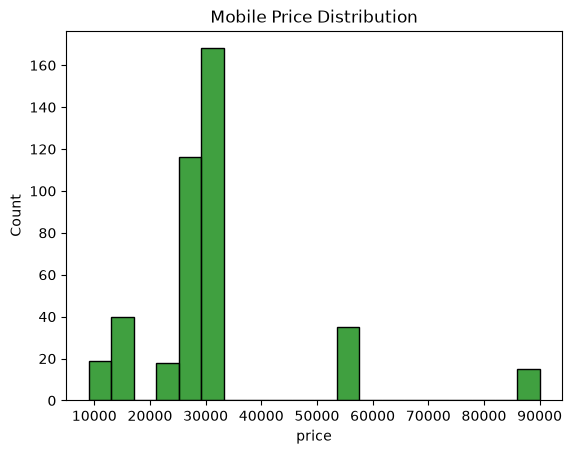

In [158]:
# Histogram: Price
sns.histplot(data=df, x="price", bins=20, color="green")
plt.title("Mobile Price Distribution")
plt.show()

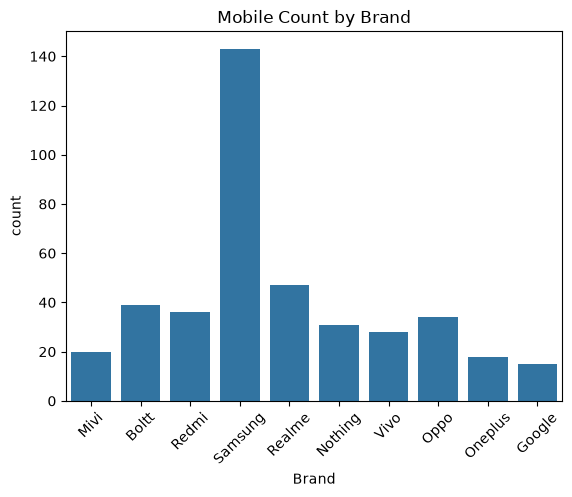

In [159]:
# Count plot: Brand
sns.countplot(data=df, x="Brand")
plt.title("Mobile Count by Brand")
plt.xticks(rotation=45)
plt.show()

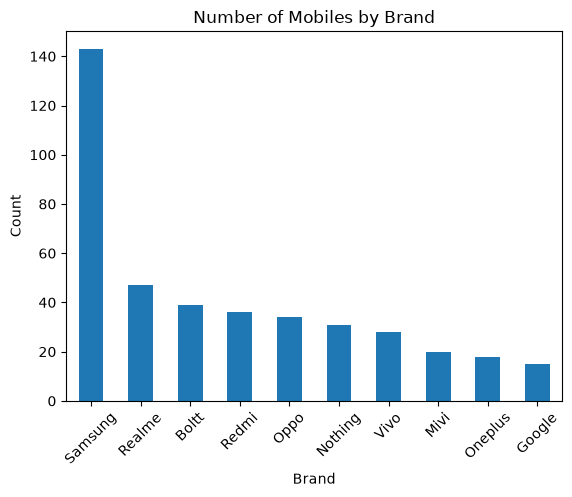

In [93]:
import matplotlib.pyplot as plt

df["Brand"].value_counts().plot(kind="bar")

plt.title("Number of Mobiles by Brand")
plt.xlabel("Brand")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

# bivariate analysis

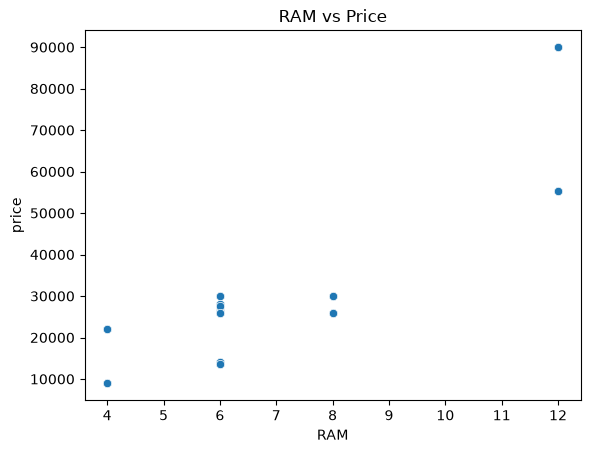

In [160]:
# Scatter plot: RAM vs Price
sns.scatterplot(data=df, x="RAM", y="price")
plt.title("RAM vs Price")
plt.show()

In [4]:
sns.scatterplot(data=df, x="RAM", y="price", color="green")

plt.title("Price vs RAM")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")
plt.ylim(0, 30000)
plt.show()

NameError: name 'df' is not defined

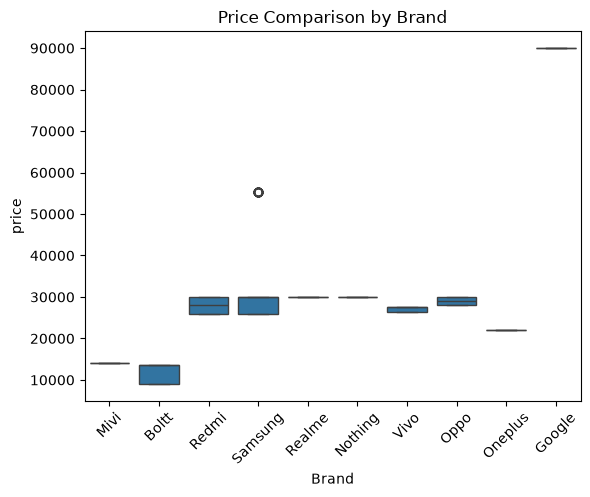

In [161]:
# Box plot: Brand vs Price
sns.boxplot(data=df, x="Brand", y="price")
plt.title("Price Comparison by Brand")
plt.xticks(rotation=45)
plt.show()

# multi variate analisis

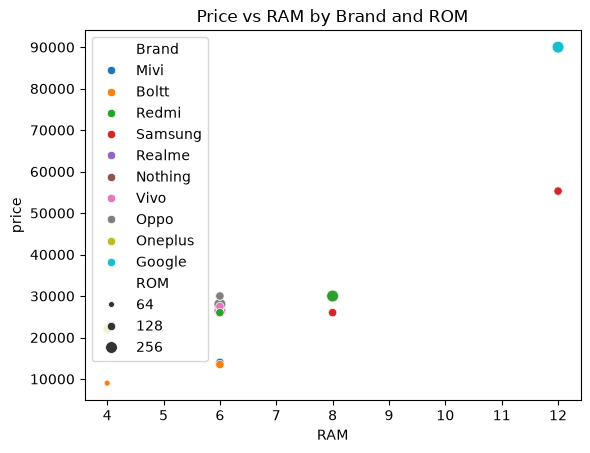

In [162]:
sns.scatterplot(
    data=df,
    x="RAM",
    y="price",
    hue="Brand",
    size="ROM"
)
plt.title("Price vs RAM by Brand and ROM")
plt.show()

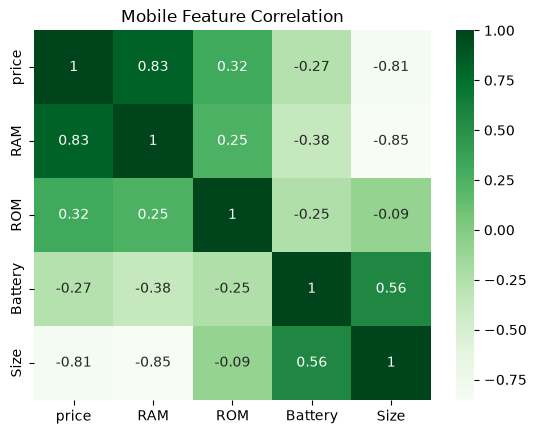

In [163]:
numeric_df = df[["price", "RAM", "ROM", "Battery", "Size"]]

sns.heatmap(numeric_df.corr(), annot=True, cmap="Greens")
plt.title("Mobile Feature Correlation")
plt.show()

In [ ]:
S

In [94]:
df.groupby("Brand")["price"].mean().sort_values(ascending=False)

Brand
Google     89999.000000
Samsung    34708.790210
Realme     29999.000000
Nothing    29999.000000
Oppo       28999.000000
Redmi      27999.000000
Vivo       27034.714286
Oneplus    22049.000000
Mivi       13999.000000
Boltt      11306.692308
Name: price, dtype: float64

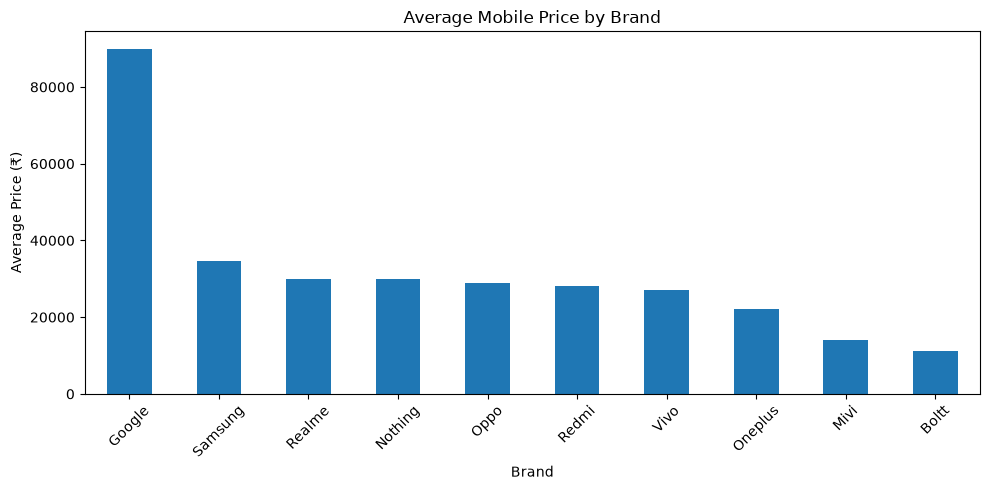

In [95]:
import matplotlib.pyplot as plt

avg_price = df.groupby("Brand")["price"].mean().sort_values(ascending=False)

avg_price.plot(kind="bar", figsize=(10, 5))

plt.title("Average Mobile Price by Brand")
plt.xlabel("Brand")
plt.ylabel("Average Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Analyse the price distribution

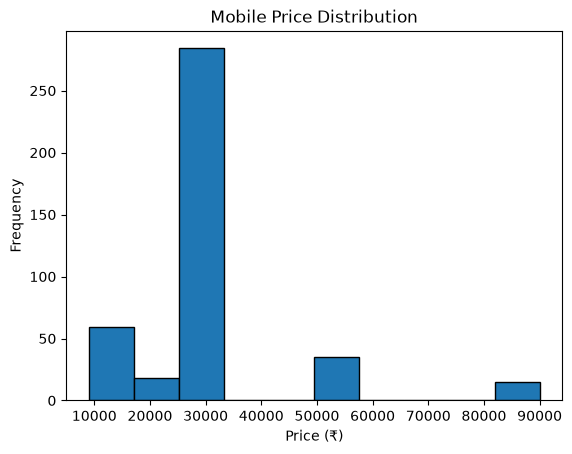

In [134]:
df["price"].plot(kind="hist", bins=10, edgecolor="black")

plt.title("Mobile Price Distribution")
plt.xlabel("Price (₹)")
plt.ylabel("Frequency")
plt.show()

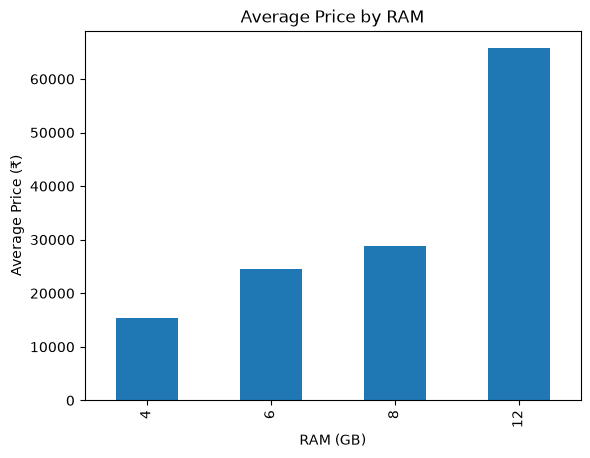

In [97]:
#  Check the relationship between RAM and price
df.groupby("RAM")["price"].mean().plot(kind="bar")

plt.title("Average Price by RAM")
plt.xlabel("RAM (GB)")
plt.ylabel("Average Price (₹)") 
plt.show()

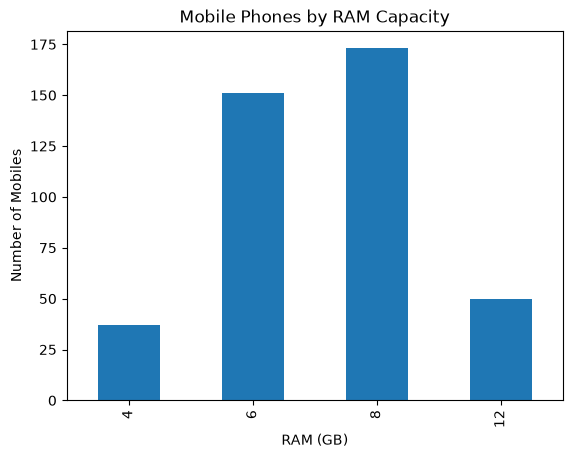

In [98]:
#  Visualise RAM distribution
df["RAM"].value_counts().sort_index().plot(kind="bar")

plt.title("Mobile Phones by RAM Capacity")
plt.xlabel("RAM (GB)")
plt.ylabel("Number of Mobiles")
plt.show()

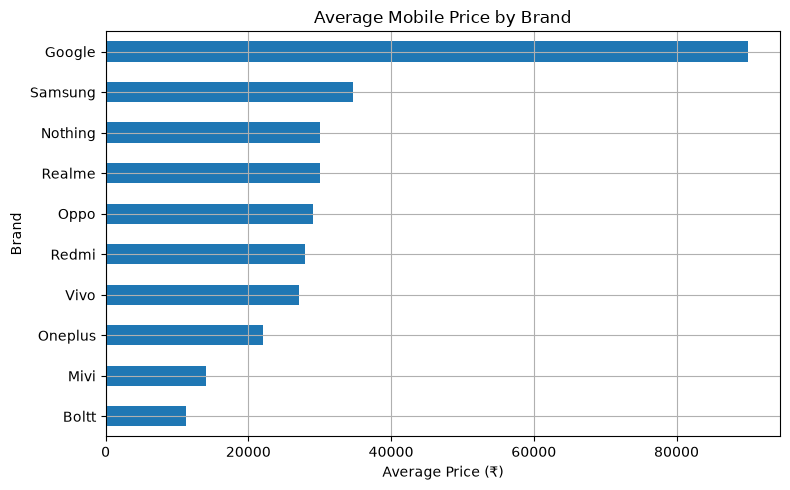

In [106]:
avg_price = df.groupby("Brand")["price"].mean().sort_values()

avg_price.plot(kind="barh", title="Average Mobile Price by Brand",
               xlabel="Average Price (₹)", ylabel="Brand",
               figsize=(8, 5), grid=True)

plt.tight_layout()
plt.show()

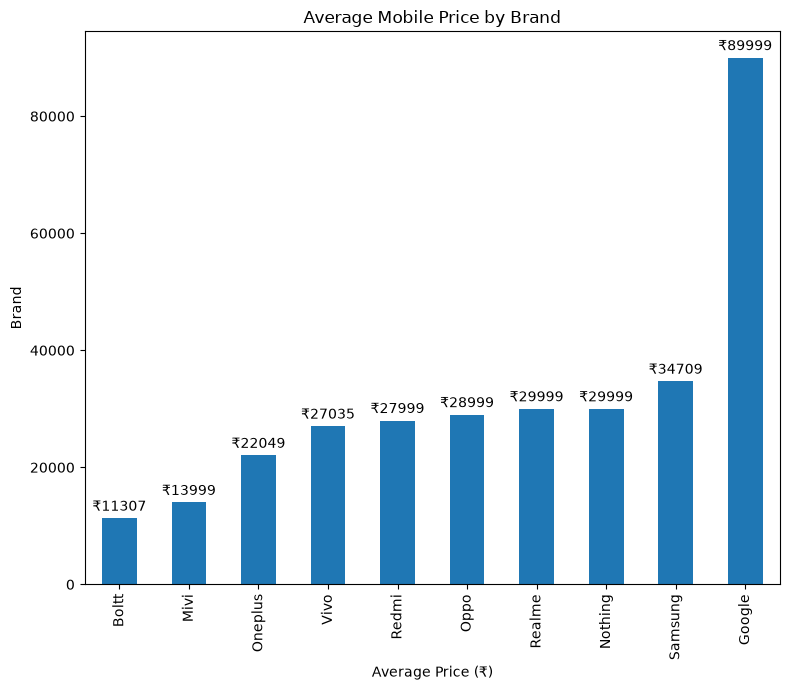

In [113]:
avg_price = df.groupby("Brand")["price"].mean().sort_values()

ax = avg_price.plot(kind="bar", figsize=(8, 7), title="Average Mobile Price by Brand")

ax.set_xlabel("Average Price (₹)")
ax.set_ylabel("Brand")
ax.bar_label(ax.containers[0], fmt="₹%.0f", padding=3)

plt.tight_layout()
plt.show()

In [117]:
print(df["Brand"].value_counts())
print(df[["Brand", "Model", "price"]].head(10))

Brand
Samsung    143
Realme      47
Boltt       39
Redmi       36
Oppo        34
Nothing     31
Vivo        28
Mivi        20
Oneplus     18
Google      15
Name: count, dtype: int64
     Brand                                              Model  price
0     Mivi                        Mivi One 5G (Green, 128 GB)  13999
1    Boltt              BOLTT ACE 5G (Midnight Black, 128 GB)  13499
2    Redmi  REDMI Note 15 SE 5G Snapdragon (Crimson Reserv...  25999
3  Samsung          Samsung Galaxy A36 5G (Dark Blue, 128 GB)  25999
4   Realme  realme P4 Power 5G Charger in the Box (TransSi...  29999
5    Boltt                        BOLTT EVO (Sky Blue, 64 GB)   8999
6  Nothing                 Nothing Phone (4b) (White, 128 GB)  29999
7     Vivo                 vivo T5x 5G (Cosmic Green, 128 GB)  27499
8     Oppo              OPPO K14 Plus 5G (Star White, 128 GB)  29999
9  Oneplus                 OnePlus N6 5G (Fresh Mint, 128 GB)  22049


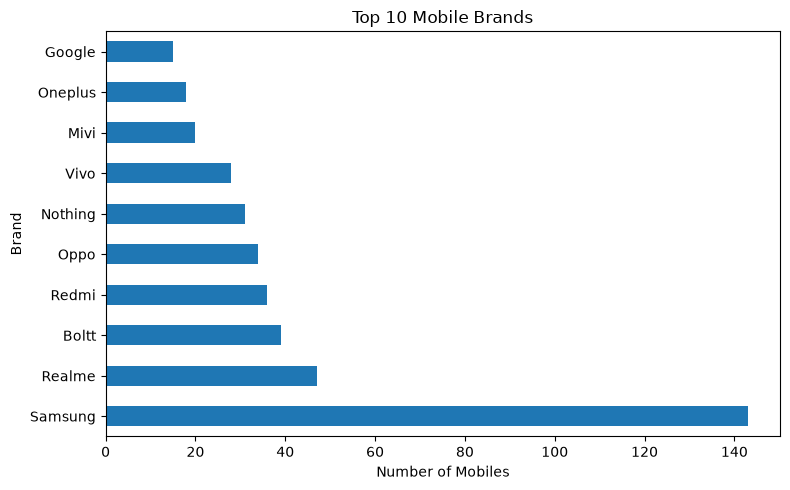

In [119]:
top_brands = df["Brand"].value_counts().head(10)

ax = top_brands.plot(
    kind="barh",
    figsize=(8, 5),
    title="Top 10 Mobile Brands"
)

ax.set_xlabel("Number of Mobiles")
ax.set_ylabel("Brand")

plt.tight_layout()
plt.show()

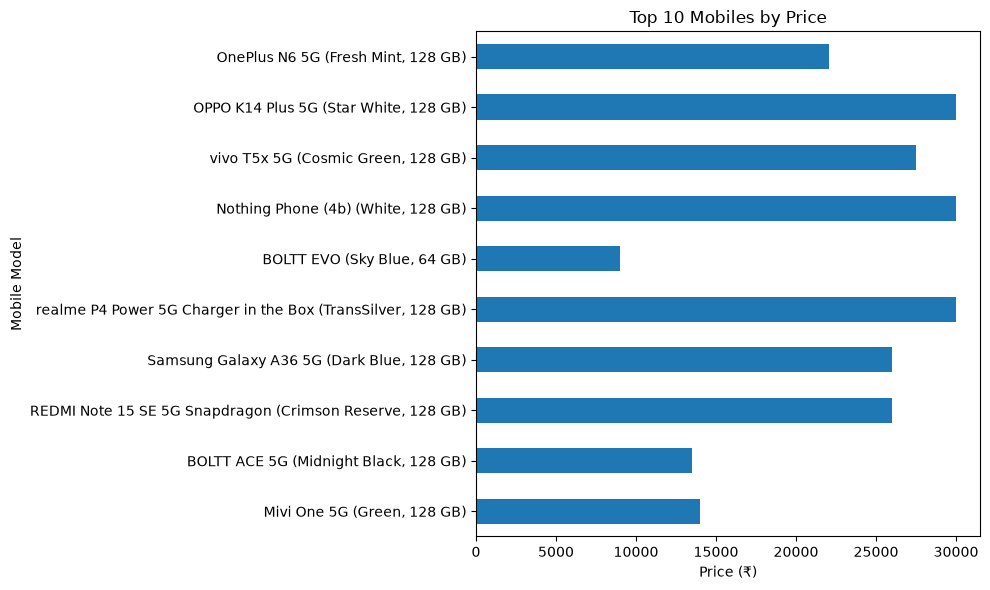

In [120]:
top10 = df.head(10)

ax = top10.plot(
    x="Model",
    y="price",
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Mobiles by Price",
    legend=False
)

ax.set_xlabel("Price (₹)")
ax.set_ylabel("Mobile Model")

plt.tight_layout()
plt.show()

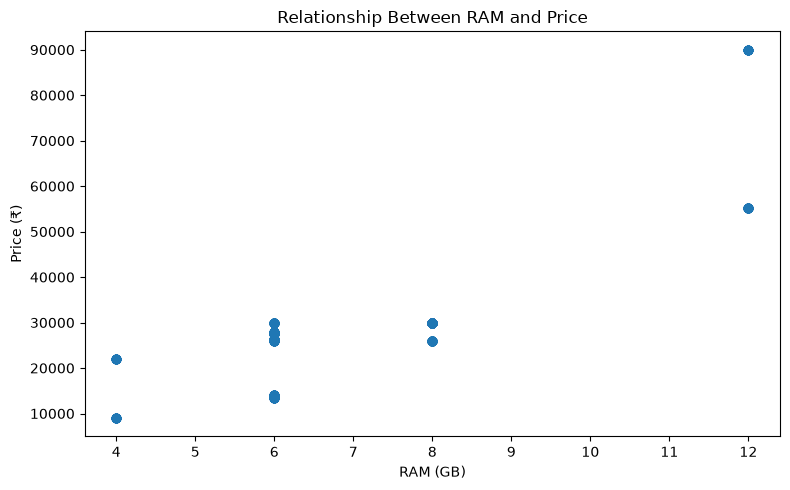

In [121]:
plt.figure(figsize=(8, 5))

plt.scatter(df["RAM"], df["price"])

plt.title("Relationship Between RAM and Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")

plt.tight_layout()
plt.show()

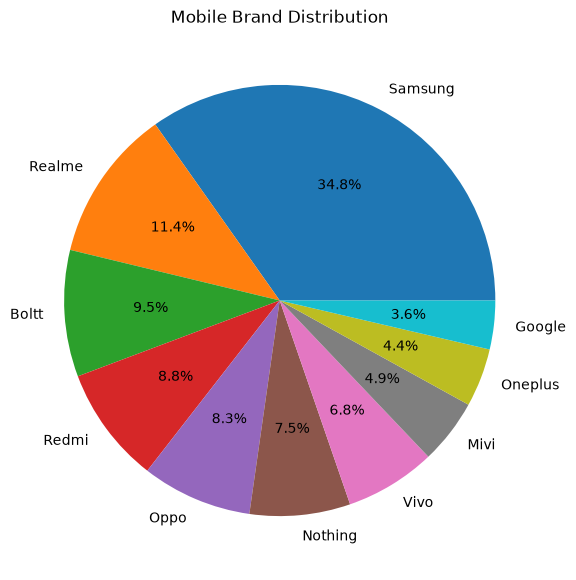

In [122]:
df["Brand"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    title="Mobile Brand Distribution"
)

plt.ylabel("")
plt.show()

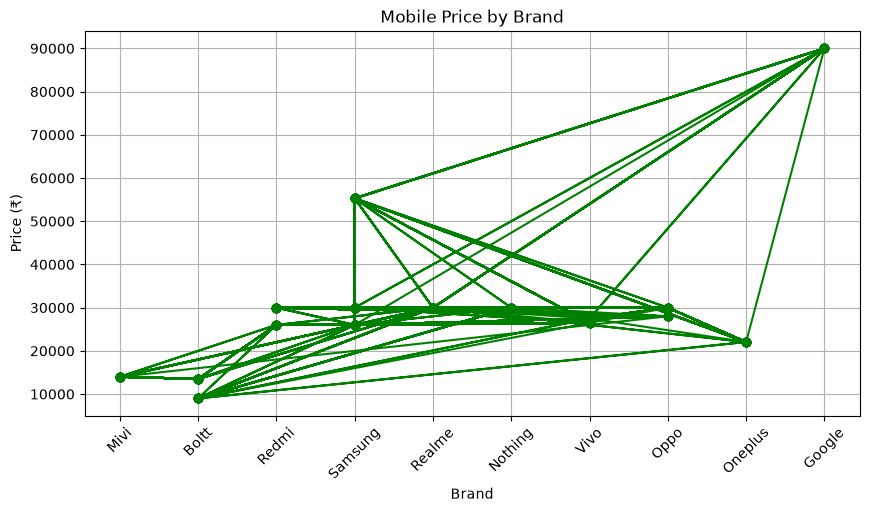

In [135]:
plt.figure(figsize=(10, 5))

plt.plot(df['Brand'], df['price'], color='green', marker='o')

plt.title('Mobile Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Price (₹)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

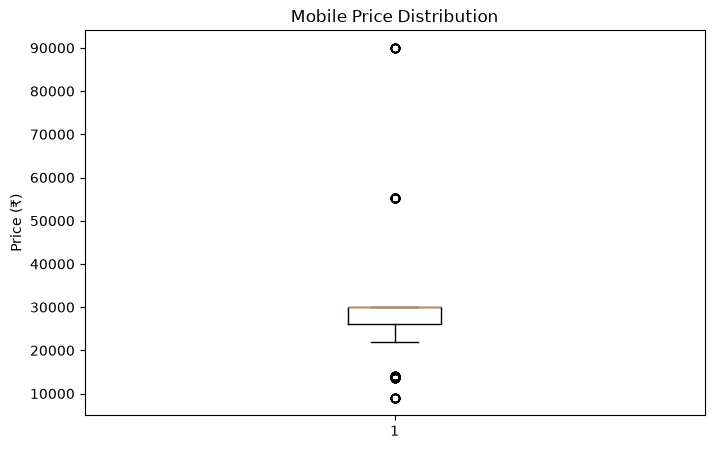

In [123]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["price"].dropna())
plt.title("Mobile Price Distribution")
plt.ylabel("Price (₹)")
plt.show()

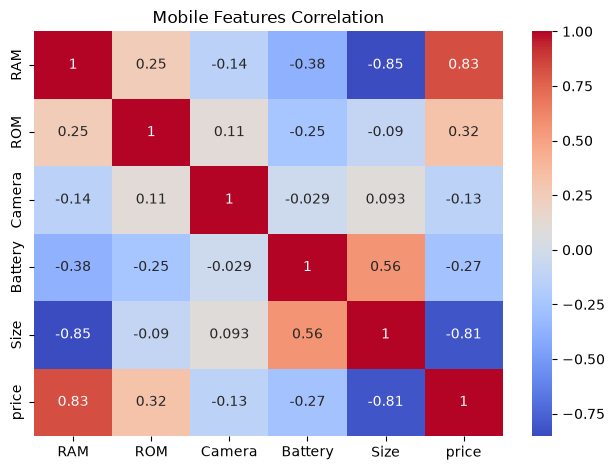

In [125]:
import seaborn as sns

numeric_df = df[["RAM", "ROM", "Camera", "Battery", "Size", "price"]].copy()
numeric_df["Camera"] = pd.to_numeric(
    numeric_df["Camera"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

sns.heatmap(numeric_df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Mobile Features Correlation")
plt.tight_layout()
plt.show()

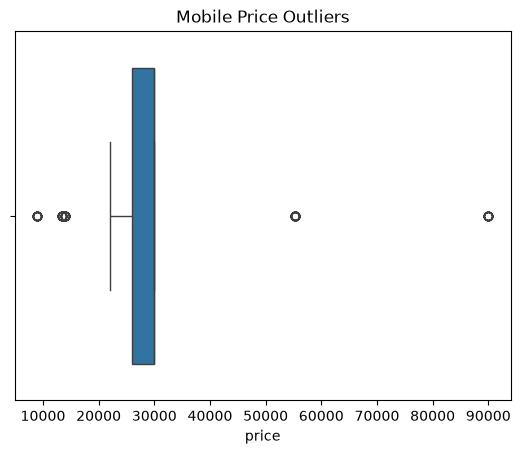

In [126]:
sns.boxplot(x=df["price"])
plt.title("Mobile Price Outliers")
plt.show()

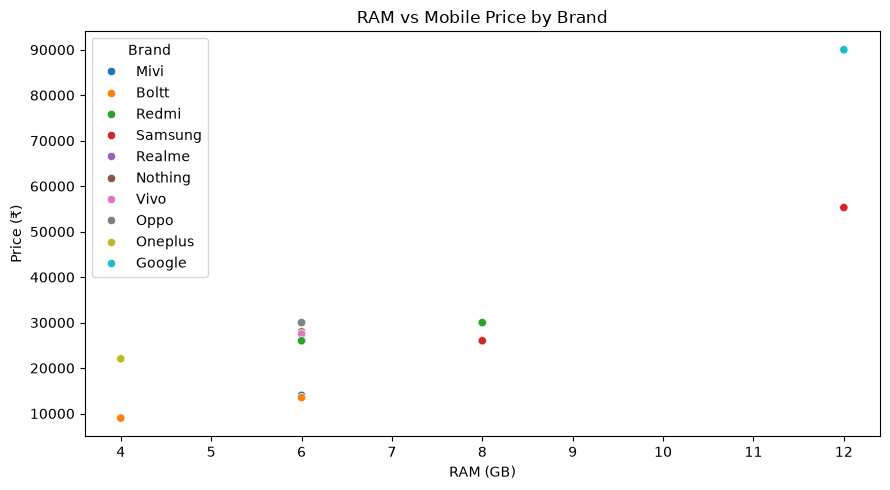

In [129]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="RAM",
    y="price",
    hue="Brand"
)

plt.title("RAM vs Mobile Price by Brand")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (₹)")
plt.tight_layout()
plt.show()

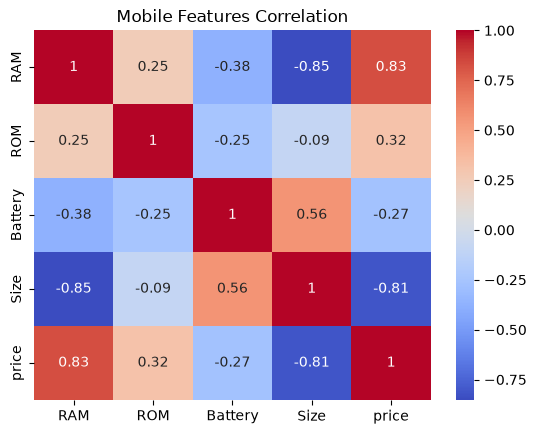

In [128]:
numeric_df = df[["RAM", "ROM", "Battery", "Size", "price"]]

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Mobile Features Correlation")
plt.show()

In [136]:
df.to_csv("flipkart_mobiles.csv", index=False)

In [137]:
import os
print(os.getcwd())

C:\Users\Sravani\sravani546\web scraping


In [138]:
pd.read_csv("flipkart_mobiles.csv")

,Brand,price,Model,RAM,ROM,Camera,Battery,Processor,Size
0,Mivi,13999,"Mivi One 5G (Green, 128 GB)",6,128,50MP Rear | 8MP Front,6000,Snapdragon 4 Gen 2 Processor,6.75
1,Boltt,13499,"BOLTT ACE 5G (Midnight Black, 128 GB)",6,128,64MP Rear | 8MP Front,6000,T8200 Processor,6.79
2,Redmi,25999,REDMI Note 15 SE 5G Snapdragon (Crimson Reserv...,6,128,50MP Rear | 20MP Front,5800,Snapdragon 6 Gen 3 Processor,6.77
3,Samsung,25999,"Samsung Galaxy A36 5G (Dark Blue, 128 GB)",8,128,50MP + 8MP | 12MP Front,5000,Qualcomm Snapdragon 6 Gen 3 Processor,6.70
4,Realme,29999,realme P4 Power 5G Charger in the Box (TransSi...,8,128,50MP + 2MP | 8MP Front,10001,Dimensity 7400 Ultra Processor,6.80
...,...,...,...,...,...,...,...,...,...
406,Nothing,29999,"Nothing Phone (4b) (White, 128 GB)",6,128,50MP + 10MP + 12MP | 12MP Front,6000,T7250 Processor,6.77
407,Oppo,29999,"OPPO K14 Plus 5G (Star White, 128 GB)",6,128,50MP + 8MP | 12MP Front,8000,Dimensity 7400-Turbo Processor,6.78
408,Oneplus,22049,"OnePlus N6 5G (Fresh Mint, 128 GB)",4,128,50MP + 8MP | 16MP Front,8000,Dimensity 7360 MAX Processor,6.80
409,Samsung,55299,Samsung Galaxy S25 5G Snapdragon (Silver Shado...,12,128,50MP Rear | 20MP Front,4000,8 Elite for Galaxy Processor,6.20
